# Notebook 04 — Popularity Retrieval (MVP)

**Goal:** Generate Top-100 recommendations using (A) 30-day global popularity and (B) time-decayed popularity. Evaluate Recall@20/50/100, HitRate@K, catalog coverage, and latency; export Parquet candidates.

**Data:** Notebook 02 DuckDB tables (`*_history`, `*_item_popularity`, `*_positives`) and Notebook 03 `*_enriched_examples` for consistency checks. All ranking signals are computed strictly from events **before** each split cutoff. The item universe is items observed in the 30-day history; already-viewed items are excluded for each user, matching Notebook 02's positive definition.

**Important:** This is a *capped, eligible-positive* offline benchmark, not impression-level CTR, and not an unbiased measure of all future interactions. In particular, the positive tables are capped and users with no eligible future item are absent. Do not tune on test. No model training here.

## 1. Setup (Windows / VS Code / Jupyter)
Run after Notebooks 02 and 03. Install: `python -m pip install duckdb pandas numpy pyarrow matplotlib`. Close connections to the same database in other notebooks if file locking occurs.

In [1]:
from pathlib import Path
import json, time, math
import numpy as np
import pandas as pd
import duckdb
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in (cwd, *cwd.parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Missing data/processed/notebook02.duckdb; run Notebook 02 first')
OUT = ROOT/'data'/'processed'
REPORT = ROOT/'data'/'reports'
REPORT.mkdir(parents=True, exist_ok=True)
con = duckdb.connect(str(OUT/'notebook02.duckdb'))
con.execute("SET memory_limit='4GB'")
con.execute('SET threads=4')
q = lambda p: "'" + p.as_posix().replace("'", "''") + "'"
splits = ('train','validation','test')
existing = {x[0] for x in con.execute('SHOW TABLES').fetchall()}
required = {f'{s}_{suffix}' for s in splits for suffix in ('history','positives','item_popularity','enriched_examples')}
assert required.issubset(existing), f'Missing tables: {required-existing}'
print('Project:',ROOT,'DuckDB:',duckdb.__version__)


Project: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks DuckDB: 1.5.5


## 2. Define historical item scores
Global baseline = number of interactions in the preceding 30 days. Time-decayed = sum of `exp(-ln(2) * age_days / half_life_days)` over historical events. We use **7-day half-life** as an initial setting; change using validation only. Item history from Notebook 02 is aggregated, so time decay uses raw `events_raw` timestamps (strictly `< cutoff`).

In [2]:
DAY = 86_400_000
HALF_LIFE_DAYS = 7.0
TOP_K = 100
for s in splits:
    cutoff = int(con.execute(f'SELECT MIN(cutoff_ts) FROM {s}_enriched_examples').fetchone()[0])
    assert con.execute(f'SELECT COUNT(DISTINCT cutoff_ts) FROM {s}_enriched_examples').fetchone()[0] == 1
    start = cutoff - 30*DAY
    con.execute(f"""CREATE OR REPLACE TABLE {s}_pop_scores AS
      SELECT item_id, COUNT(*)::BIGINT AS global_score,
        SUM(EXP(-LN(2.0) * (({cutoff} - ts)::DOUBLE / {DAY}) / {HALF_LIFE_DAYS})) AS decayed_score
      FROM events_raw
      WHERE ts >= {start} AND ts < {cutoff}
      GROUP BY item_id""")
    mismatch = con.execute(f"""SELECT COUNT(*) FROM {s}_pop_scores a
      FULL OUTER JOIN {s}_item_popularity b USING(item_id)
      WHERE a.item_id IS NULL OR b.item_id IS NULL OR a.global_score != b.item_30d_events""").fetchone()[0]
    assert mismatch == 0, f'{s}: global popularity does not match Notebook 02 historical counts'
    print(s, 'cutoff:',pd.to_datetime(cutoff,unit='ms',utc=True),
          'eligible catalog items:',con.execute(f'SELECT COUNT(*) FROM {s}_pop_scores').fetchone()[0])


train cutoff: 2015-07-31 19:47:53.596000+00:00 eligible catalog items: 124698
validation cutoff: 2015-08-18 18:21:27.439000+00:00 eligible catalog items: 117687
test cutoff: 2015-09-04 07:47:49.447000+00:00 eligible catalog items: 112664


## 3. Retrieval queries
We generate recommendations for users in each split’s capped positive table. For every user, exclude previously interacted items using an anti-join against the **30-day** history. Rank candidates by score, with `item_id` ascending for deterministic tie-breaking. These queries never access future labels for candidate scoring. They use positive-table user IDs only to define the evaluation cohort.

In [3]:
def make_candidates(split, method, top_k=100):
    assert split in splits and method in ('global','decayed')
    score_col = 'global_score' if method=='global' else 'decayed_score'
    table = f'{split}_pop_{method}_candidates'
    sql = f"""CREATE OR REPLACE TABLE {table} AS
      WITH users AS (SELECT DISTINCT user_id FROM {split}_positives),
      ranked AS (
        SELECT u.user_id, p.item_id, p.{score_col} AS retrieval_score,
          ROW_NUMBER() OVER (PARTITION BY u.user_id
             ORDER BY p.{score_col} DESC, p.item_id ASC) AS retrieval_rank
        FROM users u CROSS JOIN {split}_pop_scores p
        WHERE NOT EXISTS (
          SELECT 1 FROM {split}_history h
          WHERE h.user_id=u.user_id AND h.item_id=p.item_id
        )
      )
      SELECT user_id,item_id,retrieval_score,retrieval_rank,
        '{method}'::VARCHAR AS retrieval_source
      FROM ranked WHERE retrieval_rank <= {int(top_k)}"""
    con.execute(sql)
    return table

# Performance note: CROSS JOIN can be expensive for millions of users.
# Here the MVP evaluation cohort is ~3–4k users; a global sorted top-(K + max history)
# shortlist would be more efficient. We implement that optimized equivalent below.


## 4. Efficient top-K implementation
Instead of crossing every user with the entire catalog, first sort the global item scores. For each user, take the top `K + max(history_count)` items: after excluding their history, at least K items remain (if the catalog is large enough). This yields **exactly the same Top-K** as the full cross join, while reducing computation. A global upper bound is safe, though sometimes larger than needed.

In [4]:
def make_candidates_fast(split, method, top_k=100):
    assert split in splits and method in ('global','decayed')
    score_col = 'global_score' if method=='global' else 'decayed_score'
    max_seen = int(con.execute(f"""SELECT COALESCE(MAX(n),0) FROM
       (SELECT COUNT(*) AS n FROM {split}_history h
        JOIN (SELECT DISTINCT user_id FROM {split}_positives) u USING(user_id)
        GROUP BY h.user_id)""").fetchone()[0])
    catalog_size = int(con.execute(f'SELECT COUNT(*) FROM {split}_pop_scores').fetchone()[0])
    pool_size = min(catalog_size, top_k + max_seen)
    table = f'{split}_pop_{method}_candidates'
    t0=time.perf_counter()
    con.execute(f"""CREATE OR REPLACE TABLE {table} AS
      WITH users AS (SELECT DISTINCT user_id FROM {split}_positives),
      top_items AS (
        SELECT item_id,{score_col} AS retrieval_score FROM {split}_pop_scores
        ORDER BY {score_col} DESC,item_id ASC LIMIT {pool_size}
      ), eligible AS (
        SELECT u.user_id,p.item_id,p.retrieval_score
        FROM users u CROSS JOIN top_items p
        WHERE NOT EXISTS (
          SELECT 1 FROM {split}_history h
          WHERE h.user_id=u.user_id AND h.item_id=p.item_id
        )
      ), ranked AS (
        SELECT *, ROW_NUMBER() OVER(PARTITION BY user_id
          ORDER BY retrieval_score DESC,item_id ASC) AS retrieval_rank
        FROM eligible
      )
      SELECT user_id,item_id,retrieval_score,retrieval_rank,
        '{method}'::VARCHAR AS retrieval_source
      FROM ranked WHERE retrieval_rank <= {int(top_k)}""")
    elapsed=time.perf_counter()-t0
    users = int(con.execute(f'SELECT COUNT(DISTINCT user_id) FROM {split}_positives').fetchone()[0])
    actual = con.execute(f'SELECT COUNT(*),COUNT(DISTINCT user_id) FROM {table}').fetchone()
    assert actual[1]==users, f'{split}/{method}: some users have no candidates'
    assert con.execute(f"""SELECT COUNT(*) FROM {table} c JOIN {split}_history h
      ON c.user_id=h.user_id AND c.item_id=h.item_id""").fetchone()[0] == 0
    assert con.execute(f"""SELECT COUNT(*) FROM (
      SELECT user_id,COUNT(*) AS n,COUNT(DISTINCT item_id) AS distinct_n,
             MIN(retrieval_rank) AS first_rank,MAX(retrieval_rank) AS last_rank
      FROM {table} GROUP BY 1)
      WHERE n != distinct_n OR first_rank != 1 OR last_rank != n OR n > {top_k}""").fetchone()[0] == 0
    return {'split':split,'method':method,'table':table,'users':users,
            'candidate_rows':int(actual[0]),'pool_size':pool_size,
            'build_seconds':elapsed,'build_ms_per_user_amortized':elapsed*1000/max(users,1)}

runs=[]
for s in splits:
    for method in ('global','decayed'):
        result=make_candidates_fast(s,method,TOP_K)
        runs.append(result)
        print(result)
display(pd.DataFrame(runs))


{'split': 'train', 'method': 'global', 'table': 'train_pop_global_candidates', 'users': 4110, 'candidate_rows': 411000, 'pool_size': 1686, 'build_seconds': 0.6632819999995263, 'build_ms_per_user_amortized': 0.16138248175170955}
{'split': 'train', 'method': 'decayed', 'table': 'train_pop_decayed_candidates', 'users': 4110, 'candidate_rows': 411000, 'pool_size': 1686, 'build_seconds': 0.6590847999996186, 'build_ms_per_user_amortized': 0.16036126520671984}
{'split': 'validation', 'method': 'global', 'table': 'validation_pop_global_candidates', 'users': 3657, 'candidate_rows': 365700, 'pool_size': 1719, 'build_seconds': 0.6147958000001381, 'build_ms_per_user_amortized': 0.16811479354666067}
{'split': 'validation', 'method': 'decayed', 'table': 'validation_pop_decayed_candidates', 'users': 3657, 'candidate_rows': 365700, 'pool_size': 1719, 'build_seconds': 0.6075539000003118, 'build_ms_per_user_amortized': 0.16613450916059935}
{'split': 'test', 'method': 'global', 'table': 'test_pop_global_

,split,method,table,users,candidate_rows,pool_size,build_seconds,build_ms_per_user_amortized
0,train,global,train_pop_global_candidates,4110,411000,1686,0.663282,0.161382
1,train,decayed,train_pop_decayed_candidates,4110,411000,1686,0.659085,0.160361
2,validation,global,validation_pop_global_candidates,3657,365700,1719,0.614796,0.168115
3,validation,decayed,validation_pop_decayed_candidates,3657,365700,1719,0.607554,0.166135
4,test,global,test_pop_global_candidates,3572,357200,1125,0.431801,0.120885
5,test,decayed,test_pop_decayed_candidates,3572,357200,1125,0.466650,0.130641


## 5. Evaluate Recall@K and HitRate@K
**Recall@K** = number of eligible held-out positive user-item pairs retrieved / total eligible held-out positive pairs (micro average). **HitRate@K** = fraction of evaluation users with at least one positive retrieved. We also report user-macro recall. Since positives were selected and capped in Notebook 02, metrics describe this evaluation cohort only. **Do not evaluate against sampled weak negatives.**

In [5]:
def evaluate(split, method, ks=(20,50,100)):
    table=f'{split}_pop_{method}_candidates'
    pos_total, users_total = con.execute(f"""SELECT COUNT(*),COUNT(DISTINCT user_id)
       FROM {split}_positives""").fetchone()
    catalog_size=con.execute(f'SELECT COUNT(*) FROM {split}_pop_scores').fetchone()[0]
    result=[]
    for k in ks:
        hits, hit_users = con.execute(f"""SELECT COUNT(*),COUNT(DISTINCT c.user_id)
          FROM {table} c JOIN {split}_positives p
          ON c.user_id=p.user_id AND c.item_id=p.item_id
          WHERE c.retrieval_rank <= {int(k)}""").fetchone()
        macro = con.execute(f"""WITH positives AS (
             SELECT user_id,COUNT(*) AS n FROM {split}_positives GROUP BY user_id
           ), hits AS (
             SELECT c.user_id,COUNT(*) AS n FROM {table} c
             JOIN {split}_positives p ON c.user_id=p.user_id AND c.item_id=p.item_id
             WHERE c.retrieval_rank <= {int(k)} GROUP BY c.user_id
           ) SELECT AVG(COALESCE(h.n,0)::DOUBLE / p.n)
           FROM positives p LEFT JOIN hits h USING(user_id)""").fetchone()[0]
        unique_items=con.execute(f"""SELECT COUNT(DISTINCT item_id)
            FROM {table} WHERE retrieval_rank <= {int(k)}""").fetchone()[0]
        result.append({'split':split,'method':method,'k':int(k),
            'eligible_positive_pairs':int(pos_total),'users':int(users_total),
            'hits':int(hits),'recall_micro':hits/pos_total if pos_total else None,
            'recall_macro_user':float(macro) if macro is not None else None,
            'hit_rate':hit_users/users_total if users_total else None,
            'unique_recommended_items':int(unique_items),
            'catalog_coverage':unique_items/catalog_size if catalog_size else None})
    return result

metrics=[]
for s in splits:
    for method in ('global','decayed'):
        metrics.extend(evaluate(s,method))
metrics_df=pd.DataFrame(metrics)
display(metrics_df.round(5))


,split,method,k,eligible_positive_pairs,users,hits,recall_micro,recall_macro_user,hit_rate,unique_recommended_items,catalog_coverage
0,train,global,20,9362,4110,80,0.00855,0.00841,0.01703,39,0.00031
1,train,global,50,9362,4110,168,0.01794,0.01646,0.03212,92,0.00074
2,train,global,100,9362,4110,274,0.02927,0.02822,0.04964,164,0.00132
3,train,decayed,20,9362,4110,102,0.01090,0.01059,0.02068,43,0.00034
4,train,decayed,50,9362,4110,167,0.01784,0.01620,0.03090,95,0.00076
5,train,decayed,100,9362,4110,277,0.02959,0.02785,0.04866,166,0.00133
6,validation,global,20,9020,3657,113,0.01253,0.01321,0.02270,46,0.00039
7,validation,global,50,9020,3657,195,0.02162,0.02321,0.03938,95,0.00081
8,validation,global,100,9020,3657,308,0.03415,0.03588,0.05934,172,0.00146
9,validation,decayed,20,9020,3657,139,0.01541,0.01724,0.02926,43,0.00037


## 6. Visual comparison and interpretation
Inspect validation first for model choice. Test is held out for final reporting; avoid changing the half-life based on test results. Popularity often has low catalog coverage by design.

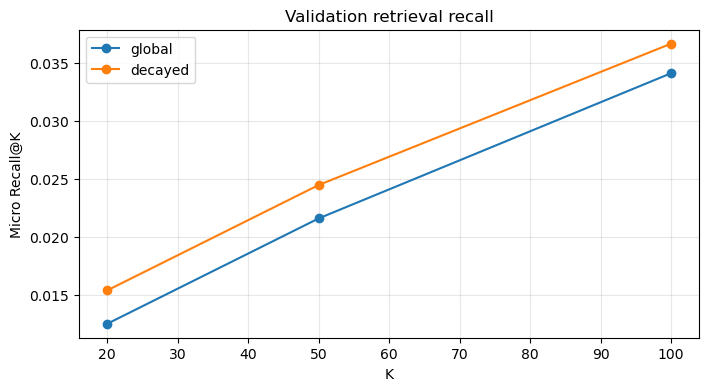

Latency note: build_seconds is batch candidate-generation wall time, not production single-request p95 latency.


In [6]:
import matplotlib.pyplot as plt
fig, ax=plt.subplots(figsize=(8,4))
for method in ('global','decayed'):
    d=metrics_df[(metrics_df.split=='validation') & (metrics_df.method==method)]
    ax.plot(d.k,d.recall_micro,marker='o',label=method)
ax.set(xlabel='K',ylabel='Micro Recall@K',title='Validation retrieval recall')
ax.legend();ax.grid(alpha=.3)
plt.show()
print('Latency note: build_seconds is batch candidate-generation wall time, not production single-request p95 latency.')


## 7. Export candidates, metrics, and report
Each Parquet row includes `user_id`, `item_id`, `retrieval_score`, `retrieval_rank`, `retrieval_source`. This format is suitable for later candidate fusion. Separate files are generated for each split and method. No future label columns are exported.

In [7]:
for s in splits:
    for method in ('global','decayed'):
        table=f'{s}_pop_{method}_candidates'
        path=OUT/f'{s}_pop_{method}_top100.parquet'
        con.execute(f'COPY {table} TO {q(path)} (FORMAT PARQUET)')
        assert path.exists() and path.stat().st_size > 0
        print(path.name, f'{path.stat().st_size/1024/1024:.2f} MiB')
metrics_df.to_csv(REPORT/'notebook04_retrieval_metrics.csv',index=False)

def json_safe(x):
    if isinstance(x,dict):return {str(k):json_safe(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):return [json_safe(v) for v in x]
    if isinstance(x,(np.integer,)):return int(x)
    if isinstance(x,(np.floating,)):return None if not np.isfinite(x) else float(x)
    if isinstance(x,float) and not math.isfinite(x):return None
    return x
report={
    'notebook':'04_popularity_retrieval',
    'half_life_days':HALF_LIFE_DAYS,
    'history_window_days':30,
    'max_k':TOP_K,
    'score_definitions':{'global':'30-day interaction count','decayed':'7-day half-life exponential decay of 30-day historical events'},
    'evaluation':'Capped eligible future positive pairs from Notebook 02; excludes 30-day seen items; no sampled negatives',
    'runs':runs,'metrics':metrics,
    'limitations':['No impression logs; metrics are not CTR or causal business impact',
                   'Positive cohort restricted to previously active users and catalog items',
                   'Capped eligible positives and single cutoff per split',
                   'Batch runtime is not production request latency',
                   'Global and decayed retrieval share the same eligible item catalog']
}
path=REPORT/'notebook04_popularity_report.json'
path.write_text(json.dumps(json_safe(report),indent=2,allow_nan=False),encoding='utf-8')
print('Report:',path)


train_pop_global_top100.parquet 0.12 MiB
train_pop_decayed_top100.parquet 0.13 MiB
validation_pop_global_top100.parquet 0.11 MiB
validation_pop_decayed_top100.parquet 0.11 MiB
test_pop_global_top100.parquet 0.10 MiB
test_pop_decayed_top100.parquet 0.11 MiB
Report: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook04_popularity_report.json


## 8. Handoff to Notebook 05 — Item-CF
Upload `data/reports/notebook04_popularity_report.json`. Next: item-item co-occurrence retrieval, cosine similarity, candidate recall comparison, and fusion. **Optimization note:** this notebook’s amortized batch latency is not a realistic online p95. Later we will benchmark warm-request serving and cached global lists.